# 02_01 Uniform and Normal

**Learning objectives**
- Understand what a **density** is and why, for a continuous variable, probability is an **area** and $P(X=x)=0$.
- Work with the **Uniform** distribution (all values in an interval equally likely) and the **Normal** distribution (the bell curve).
- Derive the normalization, mean, variance and MGF of the Normal, and use z-scores and the 68-95-99.7 rule.
- Solve three real problems (exam scores, factory tolerances, bus waiting times), each by hand, in code and by simulation, and check normality on real data.

**Prerequisites:** Module 01 (discrete distributions), in particular [01_01](../../module_01_discrete/notebooks/01_01_bernoulli_binomial.ipynb) for the normal approximation to the Binomial.

## 1. Setup

All imports live in one cell. The random generator is seeded so every run gives the same numbers. The real dataset (`tips.csv`) is read later from `../data/`; run `../data/download_data.py` if it is missing.

In [1]:
import sys
sys.path.append("../..")  # repo root, so common.style can be imported
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import plotly.graph_objects as go
from scipy import stats
from common.style import apply_style, MAIN, SIM, HIGHLIGHT, NEUTRAL, COLORS

apply_style()
rng = np.random.default_rng(42)  # fixed seed so every run gives the same numbers

## 2. Prerequisite recap

- A **continuous random variable** can take any value in an interval (a height, a waiting time), not just separate values.
- Its **probability density function (PDF)** $f(x)\ge0$ describes how probability is spread out; the total area under $f$ is 1.
- Probabilities are **areas**: $P(a\le X\le b)=\int_a^bf(x)\,dx$.
- The **CDF** is the area so far: $F(x)=P(X\le x)=\int_{-\infty}^xf(t)\,dt$, and $f(x)=F'(x)$.
- **Expected value** $E[X]=\int xf(x)dx$; **variance** $\mathrm{Var}(X)=E[(X-\mu)^2]=E[X^2]-\mu^2$.
- **Quantile (PPF):** the value $x_p$ with $F(x_p)=p$. The 90th percentile is $x_{0.9}$.

## 3. Intuition and story

### 3.1 Why density, not probability?
Measure someone's height with unlimited precision. The chance of being *exactly* 170.000000... cm is zero, because there are infinitely many possible values. What is not zero is the chance of falling in a **range**, such as 169 to 171 cm. A density tells us how crowded the values are around each point; the **area** over a range is the probability.

The picture below makes this concrete. We draw 100,000 values from a Normal distribution and plot histograms with narrower and narrower bins. Each bar's height is scaled so that the **total area is 1** (`density=True`). As the bins shrink, the bars trace out a smooth curve: that curve is the PDF.

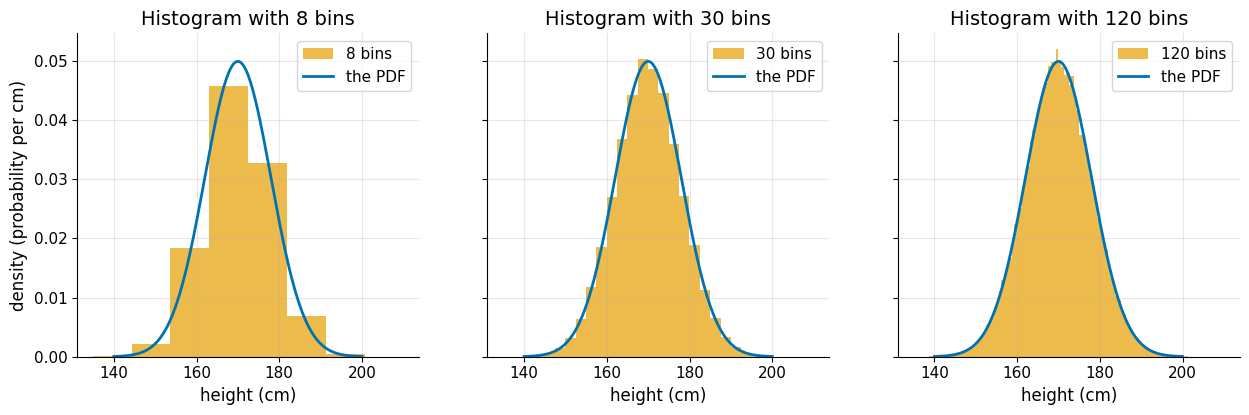

In [2]:
heights = rng.normal(loc=170, scale=8, size=100_000)       # heights in cm, mean 170, sd 8

fig, axes = plt.subplots(1, 3, figsize=(15, 4.2), sharey=True)
for ax, n_bins in zip(axes, [8, 30, 120]):
    ax.hist(heights, bins=n_bins, density=True, color=SIM, alpha=0.7, label=f"{n_bins} bins")
    x_axis = np.linspace(140, 200, 300)
    ax.plot(x_axis, stats.norm(170, 8).pdf(x_axis), color=MAIN, linewidth=2, label="the PDF")
    ax.set_title(f"Histogram with {n_bins} bins")
    ax.set_xlabel("height (cm)")
    ax.legend()
axes[0].set_ylabel("density (probability per cm)")
plt.show()

**In plain words.** The vertical axis of a PDF is *probability per unit of x* (here, per centimetre), not probability. A density can even exceed 1 (for a very narrow distribution) because only the area has to be at most 1. Always ask "what is the area over the range I care about?".

### 3.2 The two distributions in this lesson
- **Uniform:** you know only that the value lies between $a$ and $b$ and have no reason to prefer any part of the interval. Example: you arrive at a bus stop at a random moment and a bus comes every 15 minutes, so your waiting time is between 0 and 15 with no favourite value.
- **Normal (Gaussian):** the value is the sum of many small independent effects (the **Central Limit Theorem**). Heights, measurement errors, exam scores, and averages of many things all look bell shaped. It is described by two numbers: the center $\mu$ and the spread $\sigma$.

## 4. Formal definition

**Uniform($a,b$):** support $[a,b]$, parameters $a<b$.
$$f(x)=\frac1{b-a}\ (a\le x\le b),\qquad F(x)=\frac{x-a}{b-a}\ (a\le x\le b).$$

**Normal($\mu,\sigma^2$):** support $(-\infty,\infty)$, parameters $\mu\in\mathbb R$ (mean, center) and $\sigma>0$ (standard deviation, spread).
$$f(x)=\frac1{\sigma\sqrt{2\pi}}\exp\!\Big(-\frac{(x-\mu)^2}{2\sigma^2}\Big),\qquad F(x)=\Phi\Big(\frac{x-\mu}\sigma\Big),$$
where $\Phi$ is the CDF of the **standard normal** $Z\sim N(0,1)$. The CDF has no closed form; $\Phi$ is tabulated and built into every statistics library.

**z-score:** $z=\dfrac{x-\mu}\sigma$ says "how many standard deviations above the mean". If $X\sim N(\mu,\sigma^2)$ then $Z=(X-\mu)/\sigma\sim N(0,1)$. This is why a single table of $\Phi$ is enough for all Normals.

## 5. Derivations

### 5.1 Uniform: mean and variance
$$E[X]=\int_a^b\frac{x}{b-a}dx=\frac{b^2-a^2}{2(b-a)}=\frac{a+b}2,\qquad E[X^2]=\int_a^b\frac{x^2}{b-a}dx=\frac{b^3-a^3}{3(b-a)}=\frac{a^2+ab+b^2}3.$$
$$\mathrm{Var}(X)=\frac{a^2+ab+b^2}3-\frac{(a+b)^2}4=\frac{(b-a)^2}{12}.$$
The mean is the midpoint, and the variance depends only on the width. For waiting times on $[0,15]$: mean 7.5, SD $15/\sqrt{12}=4.33$.

**In plain words.** The average of a fair spread over an interval is its middle; the SD is about 29 % of the width.

### 5.2 Normal: normalization (the Gaussian integral)
We must show $\int_{-\infty}^\infty e^{-z^2/2}dz=\sqrt{2\pi}$. Let $I$ be that integral. Square it and switch to polar coordinates:
$$I^2=\iint e^{-(x^2+y^2)/2}dx\,dy=\int_0^{2\pi}\!\!\int_0^\infty e^{-r^2/2}\,r\,dr\,d\theta=2\pi\Big[-e^{-r^2/2}\Big]_0^\infty=2\pi.$$
So $I=\sqrt{2\pi}$, and substituting $z=(x-\mu)/\sigma$ shows the density integrates to 1.

### 5.3 Normal: mean
With $z=(x-\mu)/\sigma$: $E[X]=\mu+\sigma\int z\,\varphi(z)dz$. The integrand $z\,e^{-z^2/2}$ is an odd function, so its integral over the whole line is 0, hence $E[X]=\mu$.

### 5.4 Normal: variance
$\mathrm{Var}(X)=\sigma^2\int z^2\varphi(z)dz$. Integrate by parts with $u=z$, $dv=z\varphi(z)dz$ (so $v=-\varphi(z)$):
$$\int z^2\varphi(z)dz=\big[-z\varphi(z)\big]_{-\infty}^\infty+\int\varphi(z)dz=0+1=1.$$
Hence $\mathrm{Var}(X)=\sigma^2$. This shows that the parameters really are the mean and the variance.

### 5.5 Normal: MGF (completing the square)
$$M(t)=E[e^{tX}]=\int e^{tx}\frac{e^{-(x-\mu)^2/(2\sigma^2)}}{\sigma\sqrt{2\pi}}dx.$$
Combine the exponents: $tx-\frac{(x-\mu)^2}{2\sigma^2}=-\frac{(x-\mu-\sigma^2t)^2}{2\sigma^2}+\mu t+\frac{\sigma^2t^2}2$. The remaining integral is a Normal density (integral 1), so
$$M(t)=\exp\!\Big(\mu t+\frac{\sigma^2t^2}2\Big).$$
Derivatives at 0 give $M'(0)=\mu$ and $M''(0)=\mu^2+\sigma^2$.

### 5.6 Mode, skewness, kurtosis
The density is symmetric about $\mu$, so mean = median = mode = $\mu$; skewness is 0 (odd central moments vanish); the fourth central moment is $3\sigma^4$, so kurtosis is 3 and **excess kurtosis is 0**. This is the benchmark: heavier-tailed distributions have positive excess kurtosis.

### 5.7 Sum and linear transformation
If $X\sim N(\mu_1,\sigma_1^2)$ and $Y\sim N(\mu_2,\sigma_2^2)$ are independent, multiplying the MGFs gives $X+Y\sim N(\mu_1+\mu_2,\sigma_1^2+\sigma_2^2)$. Also $aX+b\sim N(a\mu+b,a^2\sigma^2)$. Normals stay Normal under addition and rescaling.

## 6. Properties and relationships

- **68-95-99.7 rule:** $P(|Z|\le1)=0.6827$, $P(|Z|\le2)=0.9545$, $P(|Z|\le3)=0.9973$. Memorize: "about two thirds within 1 SD, 95 % within 2 SD, almost everything within 3 SD".
- **Symmetry:** $\Phi(-z)=1-\Phi(z)$, so you only ever need the table for positive $z$.
- **Standardizing:** all Normals are the same shape on the z scale.
- **Central Limit Theorem (preview):** the mean of $n$ independent draws from almost any distribution is approximately Normal for large $n$. We see it in section 9.3 (full treatment in Module 05).
- **Normal approximations:** Binomial($n,p$) and Poisson($\lambda$) look Normal when $np(1-p)$ or $\lambda$ is large (lessons 01_01 and 01_03).
- **Uniform to anything:** if $U\sim\text{Uniform}(0,1)$ then $F^{-1}(U)$ has CDF $F$. This is how computers generate random numbers from other distributions (Module 12).

## 7. 2D visuals

### 7.1 The Uniform PDF and CDF
The PDF is a flat rectangle of height $1/(b-a)$; the CDF rises in a straight line from 0 to 1. The shaded rectangle is $P(4\le X\le 9)$ for a Uniform(0, 15) waiting time: width 5 times height 1/15 = 1/3.

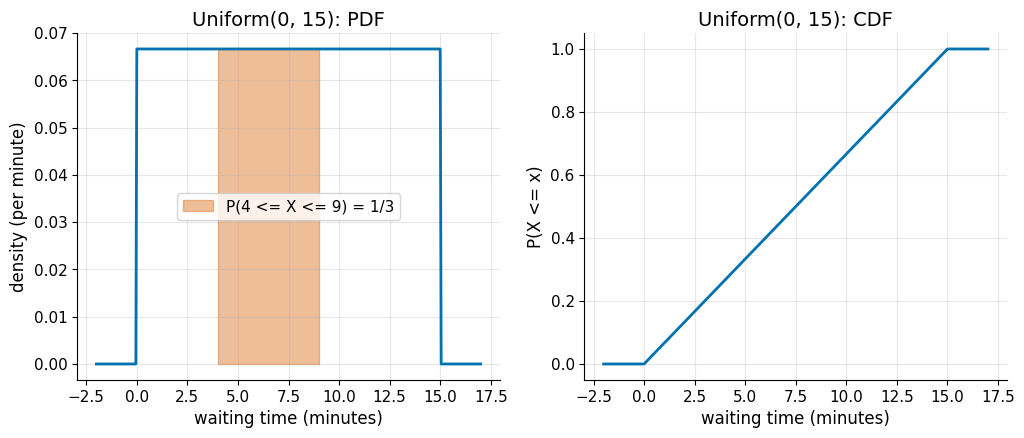

In [3]:
a, b = 0, 15                                     # waiting time between 0 and 15 minutes
wait = stats.uniform(loc=a, scale=b - a)         # scipy uses loc = a and scale = b - a
x_axis = np.linspace(-2, 17, 400)

fig, (ax_pdf, ax_cdf) = plt.subplots(1, 2, figsize=(12, 4.5))
ax_pdf.plot(x_axis, wait.pdf(x_axis), color=MAIN, linewidth=2)
inside = (x_axis >= 4) & (x_axis <= 9)
ax_pdf.fill_between(x_axis[inside], wait.pdf(x_axis[inside]), color=HIGHLIGHT, alpha=0.4, label="P(4 <= X <= 9) = 1/3")
ax_pdf.set_title("Uniform(0, 15): PDF")
ax_pdf.set_xlabel("waiting time (minutes)")
ax_pdf.set_ylabel("density (per minute)")
ax_pdf.legend()

ax_cdf.plot(x_axis, wait.cdf(x_axis), color=MAIN, linewidth=2)
ax_cdf.set_title("Uniform(0, 15): CDF")
ax_cdf.set_xlabel("waiting time (minutes)")
ax_cdf.set_ylabel("P(X <= x)")
plt.show()

### 7.2 The Normal PDF and CDF
The PDF is the bell; the CDF is the S-shaped curve of accumulated area. The mean is where the CDF equals 0.5.

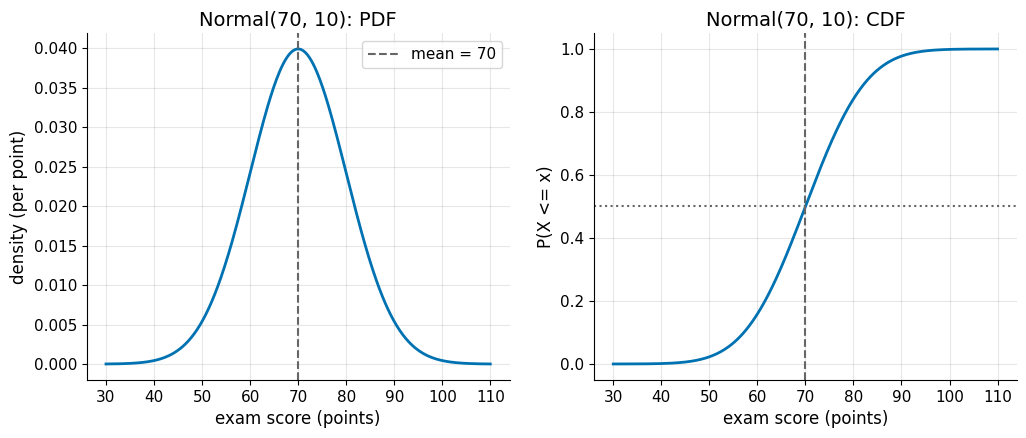

In [4]:
mu, sigma = 70, 10                                # exam scores
scores = stats.norm(loc=mu, scale=sigma)
x_axis = np.linspace(30, 110, 400)

fig, (ax_pdf, ax_cdf) = plt.subplots(1, 2, figsize=(12, 4.5))
ax_pdf.plot(x_axis, scores.pdf(x_axis), color=MAIN, linewidth=2)
ax_pdf.axvline(mu, color=NEUTRAL, linestyle="--", label="mean = 70")
ax_pdf.set_title("Normal(70, 10): PDF")
ax_pdf.set_xlabel("exam score (points)")
ax_pdf.set_ylabel("density (per point)")
ax_pdf.legend()

ax_cdf.plot(x_axis, scores.cdf(x_axis), color=MAIN, linewidth=2)
ax_cdf.axhline(0.5, color=NEUTRAL, linestyle=":")
ax_cdf.axvline(mu, color=NEUTRAL, linestyle="--")
ax_cdf.set_title("Normal(70, 10): CDF")
ax_cdf.set_xlabel("exam score (points)")
ax_cdf.set_ylabel("P(X <= x)")
plt.show()

### 7.3 Effect of the mean and of the standard deviation
**Changing mu slides the curve** left or right without changing its shape. **Changing sigma stretches it:** a small sigma gives a tall, narrow bell (values tightly packed), a large sigma a low, wide one. Because the area is always 1, narrow curves must be taller.

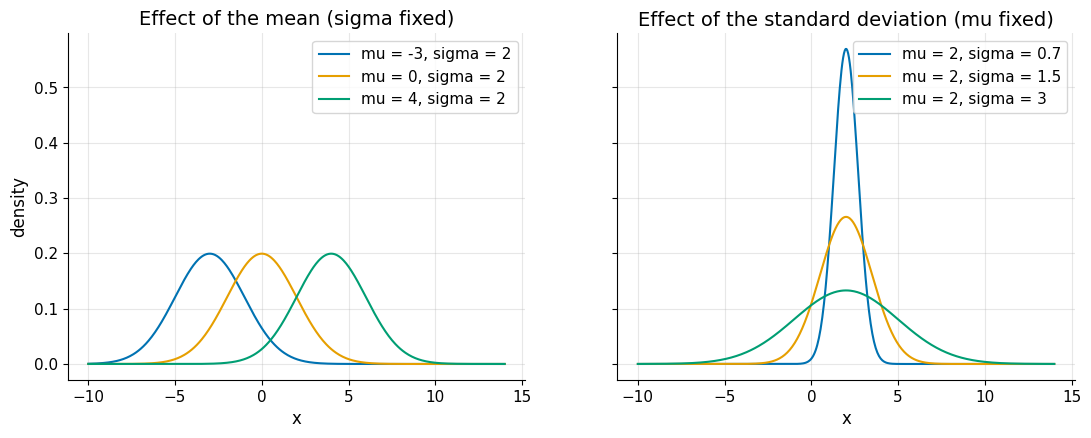

In [5]:
x_axis = np.linspace(-10, 14, 500)
fig, (ax_mu, ax_sigma) = plt.subplots(1, 2, figsize=(13, 4.5), sharey=True)
for mu_value, color in zip([-3, 0, 4], COLORS):
    ax_mu.plot(x_axis, stats.norm(mu_value, 2).pdf(x_axis), color=color, label=f"mu = {mu_value}, sigma = 2")
ax_mu.set_title("Effect of the mean (sigma fixed)")
ax_mu.set_xlabel("x")
ax_mu.set_ylabel("density")
ax_mu.legend()

for sigma_value, color in zip([0.7, 1.5, 3], COLORS):
    ax_sigma.plot(x_axis, stats.norm(2, sigma_value).pdf(x_axis), color=color, label=f"mu = 2, sigma = {sigma_value}")
ax_sigma.set_title("Effect of the standard deviation (mu fixed)")
ax_sigma.set_xlabel("x")
ax_sigma.legend()
plt.show()

### 7.4 The 68-95-99.7 rule
The shaded bands show the central 68 %, 95 % and 99.7 % of a standard normal (within 1, 2 and 3 SD of the mean).

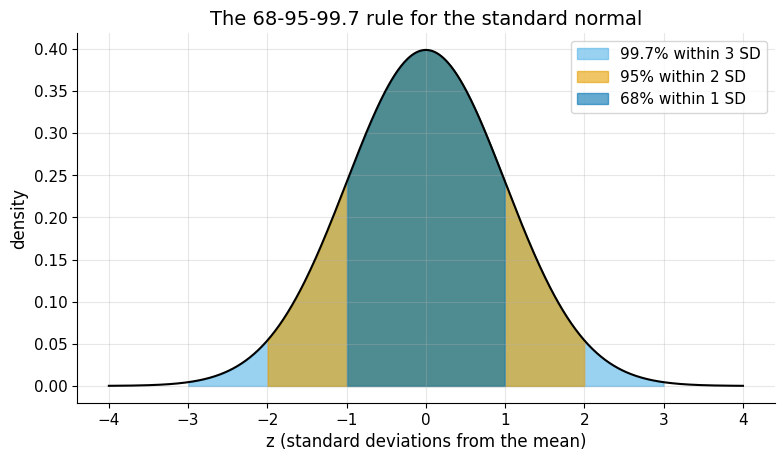

P(|Z| <= 1) = 0.6827
P(|Z| <= 2) = 0.9545
P(|Z| <= 3) = 0.9973


In [6]:
z_axis = np.linspace(-4, 4, 600)
standard = stats.norm(0, 1)
fig, ax = plt.subplots(figsize=(9, 4.8))
ax.plot(z_axis, standard.pdf(z_axis), color="black", linewidth=1.5)
for half_width, color, label in [(3, COLORS[4], "99.7% within 3 SD"), (2, COLORS[1], "95% within 2 SD"), (1, COLORS[0], "68% within 1 SD")]:
    inside = np.abs(z_axis) <= half_width
    ax.fill_between(z_axis[inside], standard.pdf(z_axis[inside]), color=color, alpha=0.6, label=label)
ax.set_title("The 68-95-99.7 rule for the standard normal")
ax.set_xlabel("z (standard deviations from the mean)")
ax.set_ylabel("density")
ax.legend()
plt.show()
for k in (1, 2, 3):
    print(f"P(|Z| <= {k}) = {standard.cdf(k) - standard.cdf(-k):.4f}")

### 7.5 Standardizing: every Normal is the same curve
A score of 85 from N(70, 10) and a height of 185 from N(170, 10) both have z = 1.5, and the same tail probability. z-scores let us compare values from different scales.

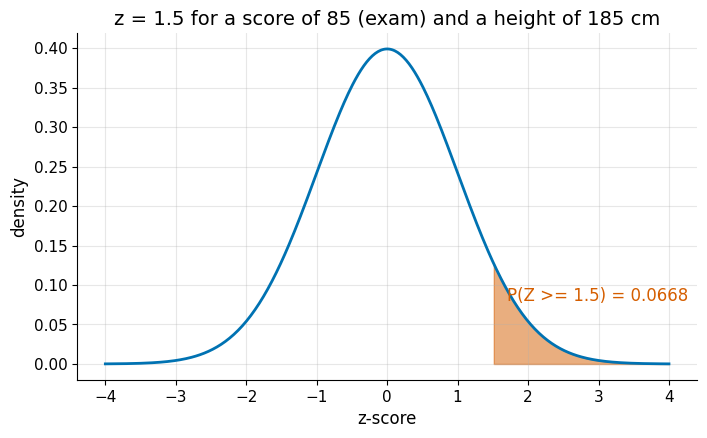

exam: P(X >= 85) = 0.0668   height: P(X >= 185) = 0.0668


In [7]:
exam = stats.norm(70, 10)
height = stats.norm(170, 10)
fig, ax = plt.subplots(figsize=(8, 4.5))
z_axis = np.linspace(-4, 4, 400)
ax.plot(z_axis, stats.norm(0, 1).pdf(z_axis), color=MAIN, linewidth=2)
ax.fill_between(z_axis[z_axis >= 1.5], stats.norm(0, 1).pdf(z_axis[z_axis >= 1.5]), color=HIGHLIGHT, alpha=0.5)
ax.set_title("z = 1.5 for a score of 85 (exam) and a height of 185 cm")
ax.set_xlabel("z-score")
ax.set_ylabel("density")
ax.text(1.7, 0.08, f"P(Z >= 1.5) = {1 - stats.norm.cdf(1.5):.4f}", color=HIGHLIGHT, fontsize=12)
plt.show()
print("exam: P(X >= 85) =", round(exam.sf(85), 4), "  height: P(X >= 185) =", round(height.sf(185), 4))

## 8. 3D visuals

### 8.1 Static: Normal PDF over (x, sigma)
For each sigma, a bell. As sigma grows the peak drops and the bell widens, always keeping area 1.

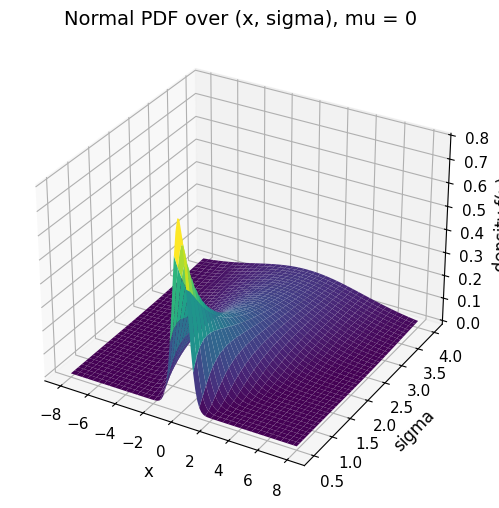

In [8]:
x_values = np.linspace(-8, 8, 120)
sigma_values = np.linspace(0.5, 4, 40)
X, S = np.meshgrid(x_values, sigma_values)
Z = stats.norm.pdf(X, loc=0, scale=S)

fig = plt.figure(figsize=(8, 6))
ax = fig.add_subplot(projection="3d")
ax.plot_surface(X, S, Z, cmap="viridis", edgecolor="none")
ax.set_title("Normal PDF over (x, sigma), mu = 0")
ax.set_xlabel("x")
ax.set_ylabel("sigma")
ax.set_zlabel("density f(x)")
ax.view_init(elev=30, azim=-60)
plt.show()

### 8.2 Static: Normal PDF over (x, mu)
Changing mu moves the ridge sideways; the shape stays the same.

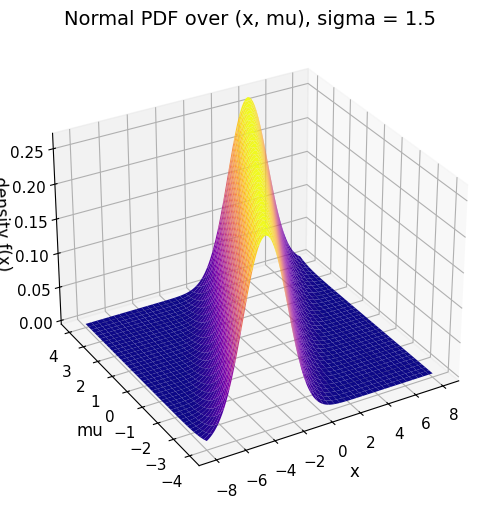

In [9]:
mu_values = np.linspace(-4, 4, 40)
X, M = np.meshgrid(x_values, mu_values)
Z_mu = stats.norm.pdf(X, loc=M, scale=1.5)

fig = plt.figure(figsize=(8, 6))
ax = fig.add_subplot(projection="3d")
ax.plot_surface(X, M, Z_mu, cmap="plasma", edgecolor="none")
ax.set_title("Normal PDF over (x, mu), sigma = 1.5")
ax.set_xlabel("x")
ax.set_ylabel("mu")
ax.set_zlabel("density f(x)")
ax.view_init(elev=30, azim=-120)
plt.show()

### 8.3 Interactive Plotly version
The (x, sigma) surface of 8.1; drag to rotate and hover to read exact densities.

In [10]:
fig = go.Figure(go.Surface(x=x_values, y=sigma_values, z=Z, colorscale="Viridis"))
fig.update_layout(title="Normal PDF over (x, sigma), mu = 0", width=750, height=550,
                  scene=dict(xaxis_title="x", yaxis_title="sigma", zaxis_title="density f(x)"))
fig.show()

## 9. Simulation vs theory

### 9.1 Histogram against the PDF
We draw 20,000 exam scores and compare the density histogram with the PDF.

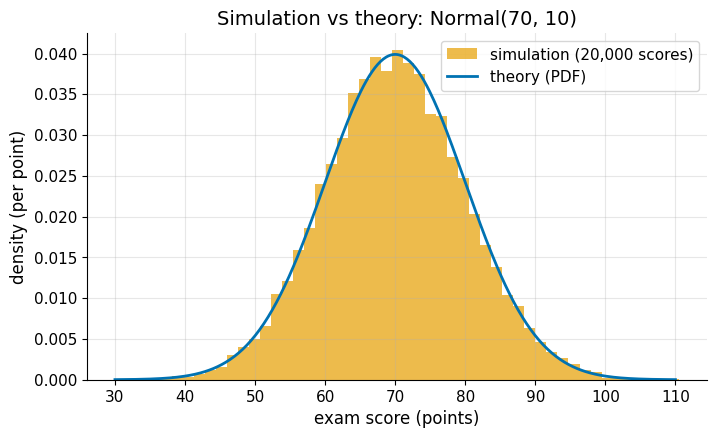

sample mean 69.99 (theory 70), sample SD 10.04 (theory 10)


In [11]:
samples = rng.normal(loc=70, scale=10, size=20_000)
x_axis = np.linspace(30, 110, 400)

fig, ax = plt.subplots()
ax.hist(samples, bins=50, density=True, color=SIM, alpha=0.7, label="simulation (20,000 scores)")
ax.plot(x_axis, scores.pdf(x_axis), color=MAIN, linewidth=2, label="theory (PDF)")
ax.set_title("Simulation vs theory: Normal(70, 10)")
ax.set_xlabel("exam score (points)")
ax.set_ylabel("density (per point)")
ax.legend()
plt.show()
print(f"sample mean {samples.mean():.2f} (theory 70), sample SD {samples.std():.2f} (theory 10)")

### 9.2 Running mean converges to mu

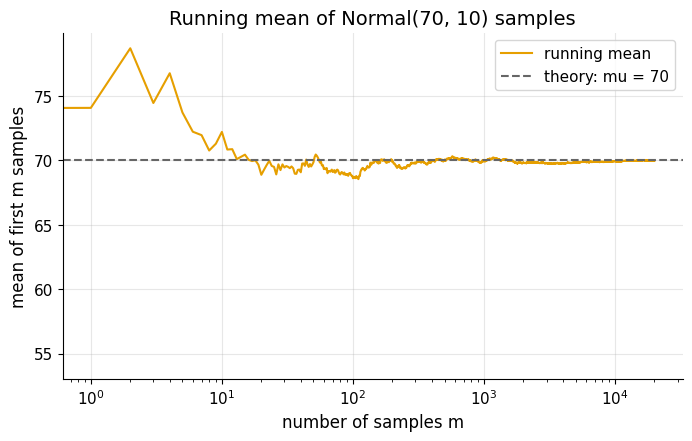

In [12]:
running_mean = np.cumsum(samples) / np.arange(1, len(samples) + 1)
fig, ax = plt.subplots()
ax.plot(running_mean, color=SIM, label="running mean")
ax.axhline(70, color=NEUTRAL, linestyle="--", label="theory: mu = 70")
ax.set_title("Running mean of Normal(70, 10) samples")
ax.set_xlabel("number of samples m")
ax.set_ylabel("mean of first m samples")
ax.set_xscale("log")
ax.legend()
plt.show()

### 9.3 The Central Limit Theorem in action
Uniform data are flat, nothing like a bell. But the **average of n uniform values** becomes bell shaped as n grows. Below, each histogram has 20,000 averages. The red curve is the Normal predicted by the CLT: mean 0.5 and SD $\sqrt{1/12}/\sqrt n$.

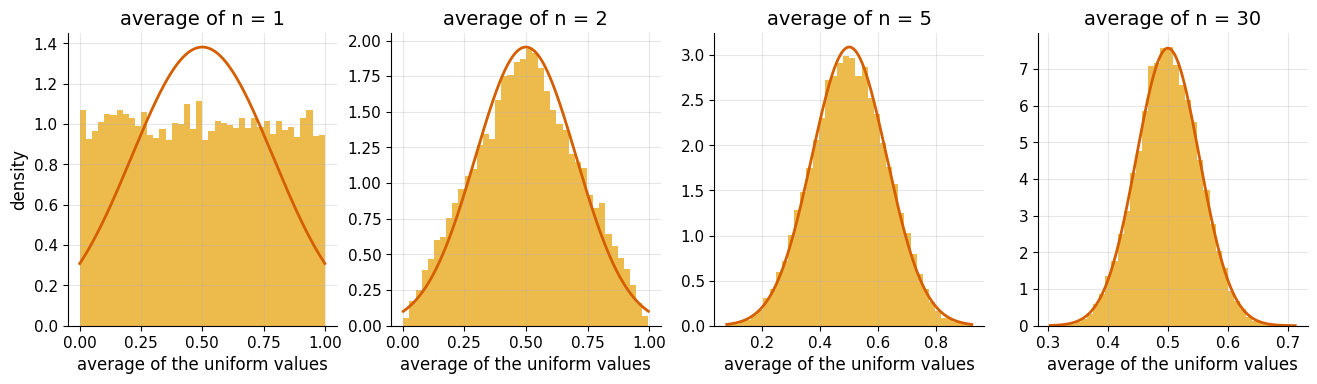

In [13]:
fig, axes = plt.subplots(1, 4, figsize=(16, 3.8), sharey=False)
for ax, n_values in zip(axes, [1, 2, 5, 30]):
    averages = rng.uniform(0, 1, size=(20_000, n_values)).mean(axis=1)
    ax.hist(averages, bins=40, density=True, color=SIM, alpha=0.7)
    grid = np.linspace(averages.min(), averages.max(), 300)
    ax.plot(grid, stats.norm(0.5, np.sqrt(1 / 12) / np.sqrt(n_values)).pdf(grid), color=HIGHLIGHT, linewidth=2)
    ax.set_title(f"average of n = {n_values}")
    ax.set_xlabel("average of the uniform values")
axes[0].set_ylabel("density")
plt.show()

**In plain words.** Even starting from a flat distribution, averaging smooths away the extremes. This is the reason the Normal is everywhere: many real quantities are sums or averages of many small effects.

## 10. `scipy.stats` cheat sheet

Uniform in `scipy` is parametrized by `loc` (the start) and `scale` (the width). Normal uses `loc` = mean and `scale` = standard deviation.

In [14]:
z = stats.norm(loc=70, scale=10)
print("pdf(70)        density at 70      :", round(z.pdf(70), 5))
print("cdf(85)        P(X <= 85)         :", round(z.cdf(85), 5))
print("sf(85)         P(X > 85)          :", round(z.sf(85), 5))
print("ppf(0.9)       90th percentile    :", round(z.ppf(0.9), 3))
print("rvs(5)         5 random draws     :", z.rvs(size=5, random_state=1).round(2))
print("mean, var      :", z.mean(), z.var())
print("interval(0.95) central 95% range  :", np.round(z.interval(0.95), 3))
print("stats          mean, var, skew, kurt:", z.stats(moments="mvsk"))

u = stats.uniform(loc=0, scale=15)
print("uniform cdf(5), ppf(0.9), mean, std:", u.cdf(5), u.ppf(0.9), u.mean(), round(u.std(), 3))

pdf(70)        density at 70      : 0.03989
cdf(85)        P(X <= 85)         : 0.93319
sf(85)         P(X > 85)          : 0.06681
ppf(0.9)       90th percentile    : 82.816
rvs(5)         5 random draws     : [86.24 63.88 64.72 59.27 78.65]
mean, var      : 70.0 100.0
interval(0.95) central 95% range  : [50.4 89.6]
stats          mean, var, skew, kurt: (np.float64(70.0), np.float64(100.0), np.float64(0.0), np.float64(0.0))
uniform cdf(5), ppf(0.9), mean, std: 0.3333333333333333 13.5 7.5 4.33


**Fitting:** `stats.norm.fit(data)` returns the maximum-likelihood estimates (sample mean and the *biased* sample SD, dividing by n).

In [15]:
data = rng.normal(70, 10, size=500)
mu_hat, sigma_hat = stats.norm.fit(data)
print(f"true mu = 70, sigma = 10  ->  fitted mu = {mu_hat:.2f}, sigma = {sigma_hat:.2f}")

true mu = 70, sigma = 10  ->  fitted mu = 69.77, sigma = 10.08


## 11. Real-world worked examples

This lesson has **three** examples and a real-data check. Example 1 is the main one (3 questions, with all five steps). Examples 2 and 3 are shorter and use other domains.

---
### Example 1 (main): exam scores

**Scenario (illustrative numbers).** A national exam has scores that are approximately Normal with **mean 70** and **standard deviation 10**.

**Questions**
1. What fraction of students score **above 85**?
2. What fraction score **between 60 and 80**?
3. A scholarship goes to the **top 10 %**. What is the cutoff score?

### 11.1 By hand
Convert to z-scores and use the standard normal table values $\Phi(1)=0.8413$, $\Phi(1.5)=0.9332$, and the quantile $z_{0.90}=1.2816$.

**Q1.** $z=\dfrac{85-70}{10}=1.5$, so $P(X>85)=1-\Phi(1.5)=1-0.9332=0.0668$ (about 6.7 %).

**Q2.** $z_{lo}=\dfrac{60-70}{10}=-1$ and $z_{hi}=\dfrac{80-70}{10}=+1$. Using symmetry, $P(60\le X\le80)=\Phi(1)-\Phi(-1)=2\Phi(1)-1=2(0.8413)-1=0.6826$. This is exactly the "68 %" of the rule.

**Q3.** Top 10 % means $F(c)=0.90$. From the table $z_{0.90}=1.2816$, so $c=\mu+z\sigma=70+1.2816\times10=82.82$.

In code, "by hand" means writing $\Phi$ ourselves with the error function from the `math` module: $\Phi(z)=\tfrac12\big(1+\mathrm{erf}(z/\sqrt2)\big)$.

In [16]:
import math

mean_score = 70
sd_score = 10

def standard_normal_cdf(z):
    # Phi(z) written with the error function: 0.5 * (1 + erf(z / sqrt(2)))
    return 0.5 * (1 + math.erf(z / math.sqrt(2)))

z_85 = (85 - mean_score) / sd_score
p_above_85_hand = 1 - standard_normal_cdf(z_85)
p_60_to_80_hand = standard_normal_cdf(1) - standard_normal_cdf(-1)
cutoff_hand = mean_score + 1.2816 * sd_score            # z from the table
print(f"P(X > 85) = {p_above_85_hand:.4f}, P(60 <= X <= 80) = {p_60_to_80_hand:.4f}, cutoff = {cutoff_hand:.2f}")

P(X > 85) = 0.0668, P(60 <= X <= 80) = 0.6827, cutoff = 82.82


### 11.2 In code with `scipy`, and the asserts

In [17]:
exam = stats.norm(loc=mean_score, scale=sd_score)

p_above_85_code = exam.sf(85)                          # survival function = 1 - CDF
p_60_to_80_code = exam.cdf(80) - exam.cdf(60)
cutoff_code = exam.ppf(0.90)                           # percent-point function = inverse CDF

assert np.isclose(p_above_85_hand, p_above_85_code)
assert np.isclose(p_60_to_80_hand, p_60_to_80_code)
assert np.isclose(cutoff_hand, cutoff_code, atol=0.01)  # the table value of z has 4 decimals
print(f"P(X > 85) = {p_above_85_code:.4f}")
print(f"P(60 <= X <= 80) = {p_60_to_80_code:.4f}")
print(f"cutoff for the top 10% = {cutoff_code:.2f}")

P(X > 85) = 0.0668
P(60 <= X <= 80) = 0.6827
cutoff for the top 10% = 82.82


### 11.3 Verify by simulation
Simulate 200,000 students and measure the same quantities. The Monte Carlo estimates should match the exact answers closely.

In [18]:
simulated_scores = rng.normal(mean_score, sd_score, size=200_000)
print(f"P(X > 85):        exact {p_above_85_code:.4f}   simulated {np.mean(simulated_scores > 85):.4f}")
print(f"P(60 <= X <= 80): exact {p_60_to_80_code:.4f}   simulated {np.mean((simulated_scores >= 60) & (simulated_scores <= 80)):.4f}")
print(f"90th percentile:  exact {cutoff_code:.2f}     simulated {np.percentile(simulated_scores, 90):.2f}")
assert abs(np.mean(simulated_scores > 85) - p_above_85_code) < 0.003
assert abs(np.percentile(simulated_scores, 90) - cutoff_code) < 0.2

P(X > 85):        exact 0.0668   simulated 0.0676
P(60 <= X <= 80): exact 0.6827   simulated 0.6833
90th percentile:  exact 82.82     simulated 82.87


### 11.4 Plots with the regions shaded

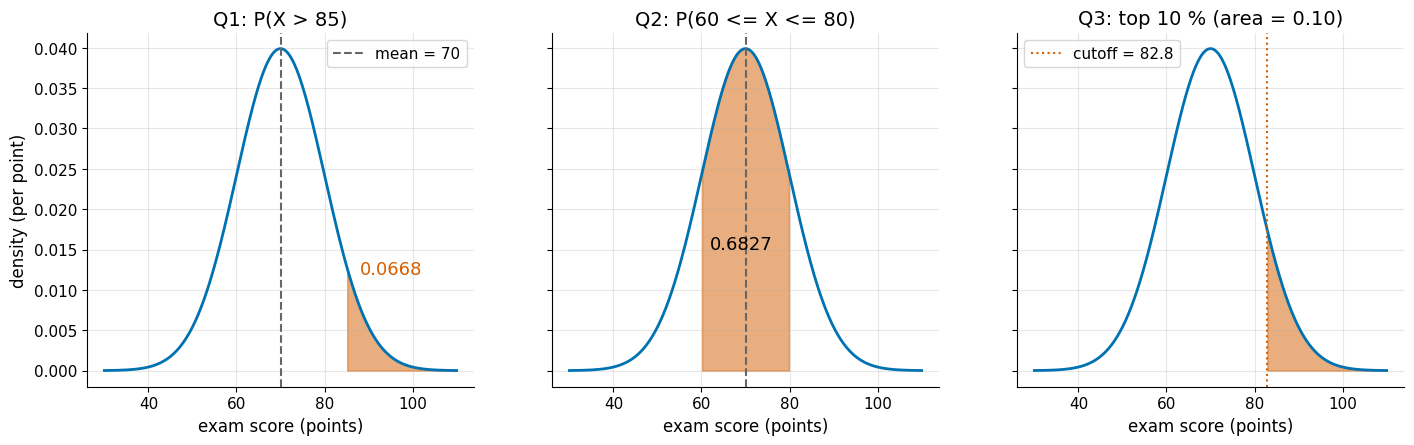

In [19]:
x_axis = np.linspace(30, 110, 500)
fig, axes = plt.subplots(1, 3, figsize=(17, 4.6), sharey=True)

# Q1: upper tail
tail = x_axis >= 85
axes[0].plot(x_axis, exam.pdf(x_axis), color=MAIN, linewidth=2)
axes[0].fill_between(x_axis[tail], exam.pdf(x_axis[tail]), color=HIGHLIGHT, alpha=0.5)
axes[0].axvline(mean_score, color=NEUTRAL, linestyle="--", label="mean = 70")
axes[0].set_title("Q1: P(X > 85)")
axes[0].text(88, 0.012, f"{p_above_85_code:.4f}", color=HIGHLIGHT, fontsize=13)
axes[0].set_xlabel("exam score (points)")
axes[0].set_ylabel("density (per point)")
axes[0].legend()

# Q2: central band
band = (x_axis >= 60) & (x_axis <= 80)
axes[1].plot(x_axis, exam.pdf(x_axis), color=MAIN, linewidth=2)
axes[1].fill_between(x_axis[band], exam.pdf(x_axis[band]), color=HIGHLIGHT, alpha=0.5)
axes[1].axvline(mean_score, color=NEUTRAL, linestyle="--")
axes[1].set_title("Q2: P(60 <= X <= 80)")
axes[1].text(62, 0.015, f"{p_60_to_80_code:.4f}", color="black", fontsize=13)
axes[1].set_xlabel("exam score (points)")

# Q3: scholarship cutoff
top = x_axis >= cutoff_code
axes[2].plot(x_axis, exam.pdf(x_axis), color=MAIN, linewidth=2)
axes[2].fill_between(x_axis[top], exam.pdf(x_axis[top]), color=HIGHLIGHT, alpha=0.5)
axes[2].axvline(cutoff_code, color=HIGHLIGHT, linestyle=":", label=f"cutoff = {cutoff_code:.1f}")
axes[2].set_title("Q3: top 10 % (area = 0.10)")
axes[2].set_xlabel("exam score (points)")
axes[2].legend()
plt.show()

### 11.5 Interpretation and decision
- About **1 student in 15** scores above 85. A score of 85 is "unusual but not rare": it is 1.5 SD above the mean.
- About **two thirds** of students score within 10 points of the average (60 to 80).
- **Decision:** set the scholarship cutoff at **83** (82.8 rounded up). That gives awards to about 10 % of the students and the rule is easy to explain: "the top tenth of the class".

---
### Example 2: shaft diameter in a factory

**Scenario (illustrative).** A machine makes steel shafts. The diameter is Normal with **target mean 25.00 mm** and **SD 0.02 mm**. Customers accept diameters between **24.96 and 25.04 mm** (the specification limits).

**Questions:** (a) what share of shafts is out of specification? (b) the machine drifts so the mean becomes 25.01 mm: what now? (c) how small must the SD be so that fewer than 1 shaft in 10,000 fails (with the mean on target)?

**By hand.** The limits are $\pm0.04$ mm $=\pm2$ SD from the target, so the defect rate is $2(1-\Phi(2))=2(1-0.97725)=0.0455$. With mean 25.01 the z-scores of the limits become $(24.96-25.01)/0.02=-2.5$ and $(25.04-25.01)/0.02=+1.5$, so the defect rate is $\Phi(-2.5)+1-\Phi(1.5)=0.0062+0.0668=0.0730$. For (c) we need $2(1-\Phi(0.04/\sigma))\le0.0001$, i.e. $0.04/\sigma\ge z_{0.99995}=3.891$, so $\sigma\le0.01028$ mm.

In [20]:
target_mean, spec_low, spec_high = 25.00, 24.96, 25.04
sigma_machine = 0.02

defect_rate_hand = 2 * (1 - standard_normal_cdf((spec_high - target_mean) / sigma_machine))
drift_rate_hand = standard_normal_cdf((spec_low - 25.01) / sigma_machine) + 1 - standard_normal_cdf((spec_high - 25.01) / sigma_machine)

on_target = stats.norm(target_mean, sigma_machine)
drifted = stats.norm(25.01, sigma_machine)
defect_rate_code = on_target.cdf(spec_low) + on_target.sf(spec_high)
drift_rate_code = drifted.cdf(spec_low) + drifted.sf(spec_high)
sigma_needed = 0.04 / stats.norm.ppf(1 - 0.0001 / 2)

assert np.isclose(defect_rate_hand, defect_rate_code)
assert np.isclose(drift_rate_hand, drift_rate_code)
print(f"defect rate on target: {defect_rate_code:.4f} ({defect_rate_code * 1e6:.0f} per million)")
print(f"defect rate after drift to 25.01: {drift_rate_code:.4f}")
print(f"SD needed for fewer than 1 in 10,000 defects: {sigma_needed:.5f} mm")
cp = (spec_high - spec_low) / (6 * sigma_machine)
cpk = min(spec_high - 25.01, 25.01 - spec_low) / (3 * sigma_machine)
print(f"process capability Cp = {cp:.2f}; after the drift Cpk = {cpk:.2f} (rule of thumb: want at least 1.33)")

defect rate on target: 0.0455 (45500 per million)
defect rate after drift to 25.01: 0.0730
SD needed for fewer than 1 in 10,000 defects: 0.01028 mm
process capability Cp = 0.67; after the drift Cpk = 0.50 (rule of thumb: want at least 1.33)


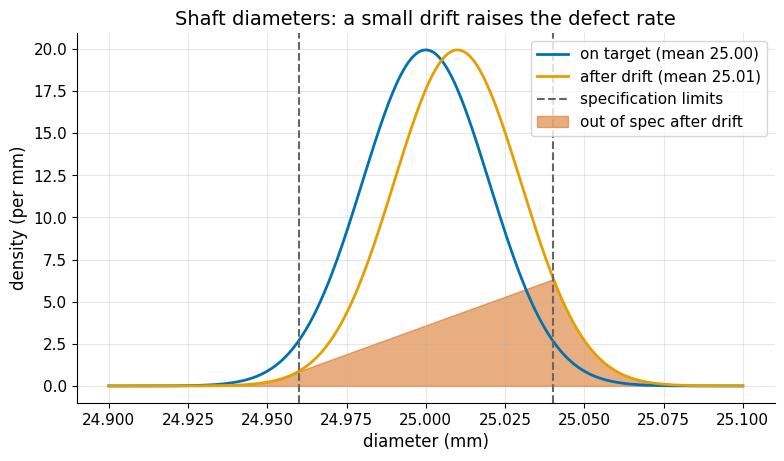

In [21]:
diameters = np.linspace(24.9, 25.1, 500)
fig, ax = plt.subplots(figsize=(9, 4.8))
ax.plot(diameters, on_target.pdf(diameters), color=MAIN, linewidth=2, label="on target (mean 25.00)")
ax.plot(diameters, drifted.pdf(diameters), color=SIM, linewidth=2, label="after drift (mean 25.01)")
ax.axvline(spec_low, color=NEUTRAL, linestyle="--")
ax.axvline(spec_high, color=NEUTRAL, linestyle="--", label="specification limits")
outside = (diameters < spec_low) | (diameters > spec_high)
ax.fill_between(diameters[outside], drifted.pdf(diameters[outside]), color=HIGHLIGHT, alpha=0.5, label="out of spec after drift")
ax.set_title("Shaft diameters: a small drift raises the defect rate")
ax.set_xlabel("diameter (mm)")
ax.set_ylabel("density (per mm)")
ax.legend()
plt.show()

**Interpretation.** On target, 4.6 % of shafts fail. A drift of only half a standard deviation (0.01 mm) raises this to 7.3 %. To get below 1 in 10,000 the process spread must drop to about 0.010 mm (half the current value). The capability index Cp = (upper - lower limit) / (6 SD) = 0.67 says the spread is wider than the tolerance (the usual goal is at least 1.33); Cpk = 0.50 after the drift also penalizes the off-center mean. **Decision:** invest in reducing variability (better tooling), because recentering alone cannot fix a spread that is as wide as the tolerance.

---
### Example 3: waiting for a bus (Uniform)

**Scenario (illustrative).** A bus arrives every 15 minutes. You arrive at a random time, so your wait is Uniform(0, 15) minutes.

**Questions:** (a) probability of waiting less than 5 minutes? (b) more than 10? (c) the 90th percentile of the wait? (d) the expected wait and its SD?

**By hand.** The density is $1/15$ per minute. (a) $P(X<5)=5	imesrac1{15}=rac13$. (b) $P(X>10)=(15-10)	imesrac1{15}=rac13$. (c) $F(x)=x/15=0.9\Rightarrow x=13.5$ minutes. (d) mean $=7.5$ min, SD $=15/\sqrt{12}=4.33$ min.

In [22]:
wait_time = stats.uniform(loc=0, scale=15)
hand = {"P(X<5)": 5 / 15, "P(X>10)": (15 - 10) / 15, "90th percentile": 0.9 * 15, "mean": 15 / 2, "SD": 15 / math.sqrt(12)}
code = {"P(X<5)": wait_time.cdf(5), "P(X>10)": wait_time.sf(10), "90th percentile": wait_time.ppf(0.9), "mean": wait_time.mean(), "SD": wait_time.std()}
for name in hand:
    assert np.isclose(hand[name], code[name])
    print(f"{name:16s} hand = code = {code[name]:.4f}")

simulated_waits = rng.uniform(0, 15, size=200_000)
print(f"simulation: P(X<5) = {np.mean(simulated_waits < 5):.4f}, P(X>10) = {np.mean(simulated_waits > 10):.4f}, 90th pct = {np.percentile(simulated_waits, 90):.2f}")

P(X<5)           hand = code = 0.3333
P(X>10)          hand = code = 0.3333
90th percentile  hand = code = 13.5000
mean             hand = code = 7.5000
SD               hand = code = 4.3301
simulation: P(X<5) = 0.3327, P(X>10) = 0.3326, 90th pct = 13.49


**Interpretation.** You wait 7.5 minutes on average, but the *uncertainty is large* (SD 4.3): one trip in three takes more than 10 minutes. Planning with the 90th percentile means allowing **13.5 minutes** for the bus.

---
### Real data: is the restaurant bill Normal?
The Normal is a model, not a law. We check it on real data: the `total_bill` of 244 restaurant parties from the `tips` dataset (source and license in `../data/README.md`). Two tools: the **histogram with the fitted Normal**, and the **Q-Q plot** (quantile-quantile): it plots the sorted data against the quantiles a Normal would give. If the data are Normal, the points fall on a straight line.

In [23]:
import pathlib
tips_path = pathlib.Path("../data/tips.csv")
if not tips_path.exists():
    raise FileNotFoundError("Run `python ../data/download_data.py` first to download the dataset.")
tips = pd.read_csv("../data/tips.csv")
bills = tips["total_bill"].to_numpy()
mu_hat, sigma_hat = stats.norm.fit(bills)
print(f"{len(bills)} parties; mean = {mu_hat:.2f}, SD = {sigma_hat:.2f}, skewness = {stats.skew(bills):.2f}")

244 parties; mean = 19.79, SD = 8.88, skewness = 1.13


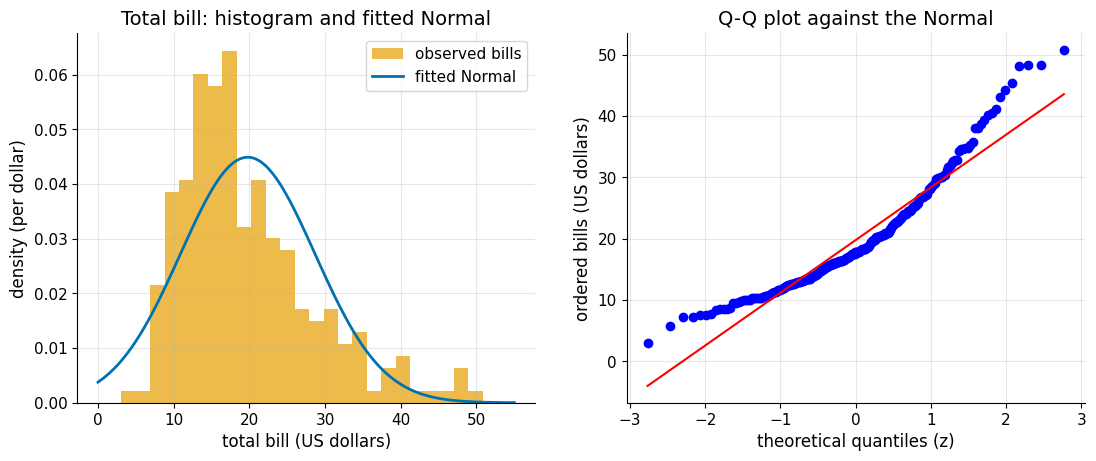

Shapiro-Wilk normality test: p-value = 3.32e-10 (small means: reject normality)


In [24]:
fig, (ax_hist, ax_qq) = plt.subplots(1, 2, figsize=(13, 4.8))
ax_hist.hist(bills, bins=25, density=True, color=SIM, alpha=0.7, label="observed bills")
grid = np.linspace(0, 55, 300)
ax_hist.plot(grid, stats.norm(mu_hat, sigma_hat).pdf(grid), color=MAIN, linewidth=2, label="fitted Normal")
ax_hist.set_title("Total bill: histogram and fitted Normal")
ax_hist.set_xlabel("total bill (US dollars)")
ax_hist.set_ylabel("density (per dollar)")
ax_hist.legend()

stats.probplot(bills, dist="norm", plot=ax_qq)
ax_qq.set_title("Q-Q plot against the Normal")
ax_qq.set_xlabel("theoretical quantiles (z)")
ax_qq.set_ylabel("ordered bills (US dollars)")
plt.show()
statistic, p_value = stats.shapiro(bills)
print(f"Shapiro-Wilk normality test: p-value = {p_value:.2e} (small means: reject normality)")

**Reading the result.** The histogram has a longer right tail than the fitted bell, and the Q-Q plot bends upward at the right end: a few big bills are much larger than a Normal predicts. The skewness (about 1.1) and the Shapiro-Wilk test agree: **bills are not Normal**. They are positive and skewed, a typical sign of a multiplicative process. That is the motivation for the next lesson, the **Lognormal** (02_02), where we will fit this same data again.

## 12. Where it is used

### Statistics
- **Confidence intervals and tests:** estimates of means are approximately Normal (CLT), giving $\bar x\pm1.96\,\mathrm{SE}$ intervals and z-tests.
- **Measurement error and regression residuals** are modelled as Normal; least squares is the maximum-likelihood fit under Normal errors.
- **Quality control:** control charts and process capability (Example 2).

### Data science
- **Standardization (z-scores)** puts features on a common scale and flags outliers beyond about 3 SD.
- **Anomaly detection baselines** and A/B test statistics rely on the Normal.
- **Uniform** is used for random sampling, random splits, and as a "no information" prior over a range.

### ML and AI
- **Weight initialization** (Xavier/He) draws weights from a Normal or Uniform with a carefully chosen scale.
- **Gaussian noise** in data augmentation, diffusion models and VAEs; the Gaussian likelihood gives the **MSE loss**.
- **Uniform(0,1)** is the source of randomness for all sampling algorithms (Module 12).

## 13. Common pitfalls and misconceptions

- **Density is not probability.** $f(70)=0.0399$ is not "a 4 % chance of scoring 70". Only areas are probabilities. Densities can exceed 1.
- **$P(X=x)=0$** for a continuous variable, so $P(X\le a)=P(X<a)$. (Unlike discrete distributions, no off-by-one worries.)
- **scipy parameters:** `norm(loc, scale)` takes the **standard deviation**, not the variance. `uniform(loc, scale)` takes the start and the **width**, not the end.
- **Not everything is Normal.** Positive, skewed or heavy-tailed data (bills, incomes, latencies) need other families. Check with a Q-Q plot.
- **68-95-99.7 is for the Normal only.** For other distributions use Chebyshev or the actual quantiles.
- **Normal tails can be too thin:** extreme events (financial crashes) are far more common than a Normal predicts (Module 02_06).
- **Sample SD uses n-1:** `np.std` divides by n by default; use `ddof=1` for the sample estimate of the population SD.

## 14. Exercises

1. For Uniform(2, 10): find the mean, the variance and $P(X>7)$.
2. Heights of adult men are Normal with mean 175 cm and SD 7 cm. What fraction is taller than 190 cm? What height is exceeded by 99 % of men?
3. A test has mean 500 and SD 100. Anna scores 640 and Ben scores 570 on a different test with mean 540 and SD 20. Who did better relative to their group?
4. If $X\sim N(10,4)$ (variance 4) and $Y\sim N(5,9)$ are independent, what is the distribution of $X-Y$? Find $P(X>Y)$.
5. Show that $E[Z^2]=1$ for the standard normal, using integration by parts.
6. Using code, find how many standard deviations around the mean contain exactly 99 % of a Normal. Compare with 3.
7. (Harder) Derive the PDF of $Y=aX+b$ for $X\sim N(\mu,\sigma^2)$ with $a>0$, using $F_Y(y)=F_X((y-b)/a)$.
8. (Harder) Use simulation to check the CLT for the average of 12 Uniform(0,1) values: compute the sample mean, SD and skewness over 100,000 averages and compare with the theory ($0.5$, $\sqrt{1/144}=0.0833$, 0).

Solutions are at the end.

## 15. Summary table

| Item | Uniform(a, b) | Normal(mu, sigma) |
|---|---|---|
| Parameters | a < b | mu (mean), sigma > 0 (SD) |
| Support | [a, b] | all real numbers |
| PDF | 1/(b-a) | exp(-(x-mu)^2 / (2 sigma^2)) / (sigma sqrt(2 pi)) |
| Mean | (a+b)/2 | mu |
| Variance | (b-a)^2/12 | sigma^2 |
| Skewness | 0 | 0 |
| Excess kurtosis | -1.2 | 0 |
| When to use | no preference within a range; random numbers | sums and averages of many small effects; measurement error |
| `scipy` name | `stats.uniform(loc=a, scale=b-a)` | `stats.norm(loc=mu, scale=sigma)` |

## Solutions

In [25]:
u = stats.uniform(2, 8)
print("1: mean", u.mean(), "var", round(u.var(), 4), "P(X>7)", u.sf(7))
men = stats.norm(175, 7)
print("2: P(>190) =", round(men.sf(190), 5), " height exceeded by 99% =", round(men.ppf(0.01), 2))
print("3: Anna z =", (640 - 500) / 100, " Ben z =", (570 - 540) / 20)
diff = stats.norm(10 - 5, np.sqrt(4 + 9))
print("4: X - Y ~ N(5, 13); P(X > Y) =", round(diff.sf(0), 4))
print("6: 99% central interval half-width =", round(stats.norm.ppf(0.995), 4), "SD")
averages = rng.uniform(0, 1, size=(100_000, 12)).mean(axis=1)
print("8: mean", averages.mean().round(4), "sd", averages.std().round(4), "(theory 0.0833) skew", round(stats.skew(averages), 3))

1: mean 6.0 var 5.3333 P(X>7) 0.375
2: P(>190) = 0.01606  height exceeded by 99% = 158.72
3: Anna z = 1.4  Ben z = 1.5
4: X - Y ~ N(5, 13); P(X > Y) = 0.9172
6: 99% central interval half-width = 2.5758 SD
8: mean 0.5 sd 0.0835 (theory 0.0833) skew 0.004


**1.** Mean $6$, variance $(10-2)^2/12=5.33$, $P(X>7)=3/8=0.375$.

**2.** $z=(190-175)/7=2.14$, so about 1.6 % are taller than 190 cm; 99 % of men are taller than $175-2.326\times7=158.7$ cm.

**3.** Anna's $z=1.4$, Ben's $z=1.5$: Ben did slightly better relative to his group even though his raw score is lower.

**4.** $X-Y\sim N(10-5,\,4+9)=N(5,13)$ (variances add even when subtracting). $P(X>Y)=P(X-Y>0)=1-\Phi(-5/\sqrt{13})=\Phi(1.387)\approx0.917$.

**5.** $\int z^2\varphi\,dz=[-z\varphi]+\int\varphi\,dz=0+1=1$ (section 5.4).

**6.** $z_{0.995}=2.576$, so 99 % lies within 2.58 SD, a bit less than 3.

**7.** $F_Y(y)=F_X\big(\tfrac{y-b}a\big)$ so $f_Y(y)=\tfrac1af_X\big(\tfrac{y-b}a\big)=\dfrac1{a\sigma\sqrt{2\pi}}\exp\!\Big(-\dfrac{(y-b-a\mu)^2}{2a^2\sigma^2}\Big)$: this is $N(a\mu+b,a^2\sigma^2)$.

**8.** The average of 12 Uniform(0,1) values has mean 0.5, SD $\sqrt{1/12}/\sqrt{12}=1/12=0.0833$ and skewness about 0 (printed): it is already very close to Normal.